# Iguaçu River at Porto Amazonas — ANA 65035000

The Iguaçu River rises on the eastern edge of the Curitiba metropolitan region, in the state of Paraná, Brazil, and flows west for about 1,300 km to the Iguaçu Falls, on the border with Argentina. Porto Amazonas lies on its upper course, about 60 km west of Curitiba.

Important facts about the station, from the Brazilian National Water Agency (ANA):

* **Code 65035000**, operated by the Paraná state environmental agency (IAT-PR). Drainage area of 3,620 km², upstream of the station.
* **Daily discharge since August 1935.** The record is consistency-checked up to 2005, then has gaps and raw (not yet checked) data until 2019.
* **A well-studied record.** Tozzi & Fill (2020) used this station's 1935–2005 series in a study of 14 Iguaçu basin gauges and found changes in mean and maximum annual flows. This notebook revisits the full record with RHIS-TS.

This notebook follows the same steps as the Potomac River notebook (`usgs.ipynb`), and the comparison is worth making: the two rivers give very different answers.

## Install and imports

In [ ]:
%pip install rhis-ts==0.2.0

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from loguru import logger

import plotting  # noqa: F401  (registers the Inter font used by all figures)
from helpers import (
    build_repr_df, build_rhis_evol_df, download_ana_daily_flows, fmt_p,
    lp3_estimate, plot_evolution, run_rhis,
)

logger.remove()  # silence rhis-ts debug messages

## Getting the data

ANA publishes Brazil's hydrological data on [HidroWeb](https://www.snirh.gov.br/hidroweb). Its public web service returns the full daily discharge record of a station, but it is slow and often answers with a time-out. To keep this notebook reproducible, a snapshot of the record (downloaded on 2026-11-05) is stored in `datasets/`. Set `DOWNLOAD = True` to fetch the latest version from ANA instead; the helper retries until the service answers.

ANA stores each month twice when it has been reviewed: as **raw** data (consistency level 1) and as **consistency-checked** data (level 2). When both exist, the checked value is kept.

In [2]:
STATION = '65035000'
SNAPSHOT = 'datasets/ana_65035000_porto_amazonas_daily.csv'
DOWNLOAD = False  # True: download from ANA (slow; can take several minutes)

if DOWNLOAD:
    data = download_ana_daily_flows(STATION)
else:
    data = pd.read_csv(SNAPSHOT, parse_dates=['date']).set_index('date')

data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 27814 entries, 1935-08-07 to 2019-09-30
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   flow               27814 non-null  float64
 1   consistency_level  27814 non-null  int64  
dtypes: float64(1), int64(1)
memory usage: 651.9 KB


In [3]:
# A continuous daily calendar: days without a measurement become NaN
calendar = pd.date_range(data.index.min(), data.index.max(), freq='D')
flow = data['flow'].reindex(calendar).rename('flow')  # daily mean discharge, m³/s
level = data['consistency_level'].reindex(calendar)

print(f'First day: {flow.first_valid_index():%Y-%m-%d}')
print(f'Last day:  {flow.last_valid_index():%Y-%m-%d}')
print(f'Days with data: {flow.notna().sum():,} of {len(flow):,} in the calendar')

First day: 1935-08-07
Last day:  2019-09-30
Days with data: 27,814 of 30,736 in the calendar


## Exploratory analysis

Before running any statistical test, it pays to *look* at the data. This section answers six practical questions:

0. **What does the series look like?**
1. **Is the record complete, and has it been checked?** Gaps and unchecked data change what the tests "see".
2. **What does a typical flow look like?**
3. **Is there a seasonal cycle?** Seasons are a common reason a streamflow series fails the randomness test.
4. **Does today's flow "remember" yesterday's?** This memory (persistence) is what the independence test detects.
5. **Are there long-term changes?** Shifts and trends are what the homogeneity and stationarity tests detect.

In [4]:
from matplotlib.ticker import StrMethodFormatter

# Colors used in this notebook (one color per role)
BLUE, ORANGE = '#2a78d6', '#eb6834'   # consistency-checked data, raw data
MUTED, GRID, GAP = '#52514e', '#e6e5e1', '#f1f0ec'


def tidy(ax):
    """Light grid, no top/right frame: keeps the eye on the data."""
    ax.grid(color=GRID, linewidth=0.8)
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color(MUTED)


def shade_gaps(ax, series, min_days=60):
    """Shade every gap longer than `min_days` days."""
    missing = series.isna()
    runs = (missing != missing.shift()).cumsum()
    for _, run in series[missing].groupby(runs[missing]):
        if len(run) >= min_days:
            ax.axvspan(run.index[0], run.index[-1], color=GAP, zorder=0)


checked = flow.where(level == 2)
raw = flow.where(level == 1)

### 0. A first look at the series

The top panel shows the whole record; shaded bands are periods without data. The bottom panel zooms in on the last 20 years, where the gaps and the change from checked to raw data happen.

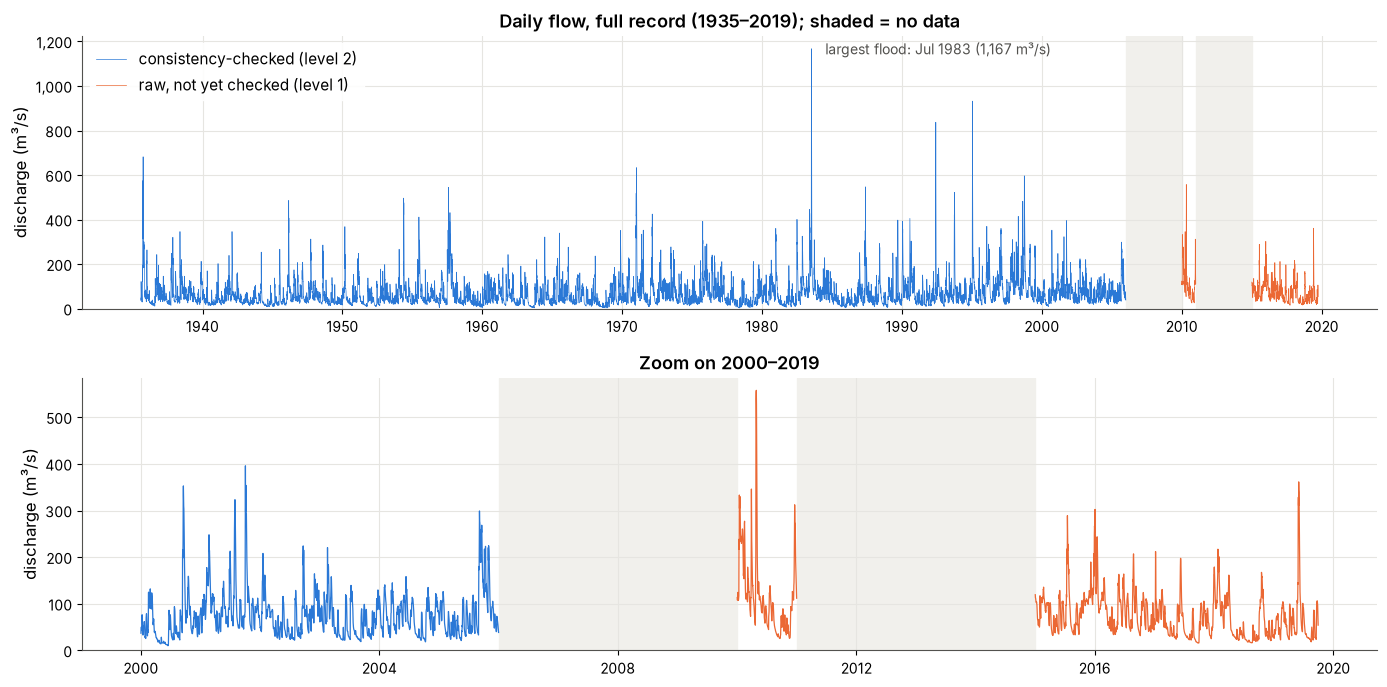

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))

for ax, window in [(axes[0], slice(None)), (axes[1], slice('2000-01-01', None))]:
    shade_gaps(ax, flow[window])
    ax.plot(checked[window].index, checked[window], color=BLUE, linewidth=0.5 if ax is axes[0] else 0.9,
            label='consistency-checked (level 2)')
    ax.plot(raw[window].index, raw[window], color=ORANGE, linewidth=0.5 if ax is axes[0] else 0.9,
            label='raw, not yet checked (level 1)')
    ax.set_ylabel('discharge (m³/s)')
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    tidy(ax)

axes[0].annotate(f'largest flood: {flow.idxmax():%b %Y} ({flow.max():,.0f} m³/s)', (flow.idxmax(), flow.max()),
                 textcoords='offset points', xytext=(10, -4), color=MUTED, fontsize=10)
axes[0].set_title(f'Daily flow, full record ({flow.first_valid_index():%Y}–{flow.last_valid_index():%Y}); shaded = no data')
axes[0].legend(loc='upper left')
axes[1].set_title('Zoom on 2000–2019')
plt.tight_layout()
plt.show()

**How to read it:** the record is a dense band of daily flows with sharp flood peaks; the largest came in July 1983. The zoom shows the two features that make this record different from a "clean" one: long gaps (2006–2009 and 2011–2014) and, from 2010 on, data that ANA has not yet consistency-checked (orange).

### 1. Is the record complete, and has it been checked?

The statistical tests read the values **in order** and do not know the dates. A gap is simply skipped: the tests see the last day before it and the first day after it as consecutive values.

In [6]:
# Contiguous stretches of data and of gaps (gaps shorter than a month are ignored)
present = flow.notna()
runs = (present != present.shift()).cumsum()
rows = []
for _, run in flow.groupby(runs):
    has_data = run.notna().iloc[0]
    if has_data or len(run) >= 31:
        levels = level[run.index].dropna().unique()
        rows.append({
            'from': f'{run.index[0]:%Y-%m-%d}',
            'to': f'{run.index[-1]:%Y-%m-%d}',
            'days': len(run),
            'content': ('data, ' + ' + '.join({1: 'raw', 2: 'checked'}[int(x)] for x in sorted(levels))) if has_data else 'NO DATA',
        })
pd.DataFrame(rows)

,from,to,days,content
0,1935-08-07,2005-12-31,25715,"data, checked"
1,2006-01-01,2009-12-31,1461,NO DATA
2,2010-01-01,2010-12-31,365,"data, raw"
3,2011-01-01,2014-12-31,1461,NO DATA
4,2015-01-01,2019-09-30,1734,"data, raw"


**How to read it:**

* **70 continuous years of checked data (1935–2005).** This is the part of the record that Tozzi & Fill (2020) analyzed.
* **Two four-year gaps (2006–2009 and 2011–2014).** The tests will read December 2005, then 2010, then January 2015 as if they followed each other.
* **Raw data since 2010.** Raw values have not been reviewed by ANA: errors in the stage–discharge relationship (the "rating curve") or in the readings may still be there. And RHIS-TS gives special weight to the most recent values.

Keep these three points in mind: section 5 of the RHIS analysis shows how much they matter.

### 2. What does a typical flow look like?

count    27814.0
mean        69.2
std         62.8
min          3.4
5%          15.3
50%         51.1
95%        178.0
max       1167.0

Lowest daily flow:  3.4 m³/s on 1968-11-29
Highest daily flow: 1,167 m³/s on 1983-07-11
The mean is 1.4x the median


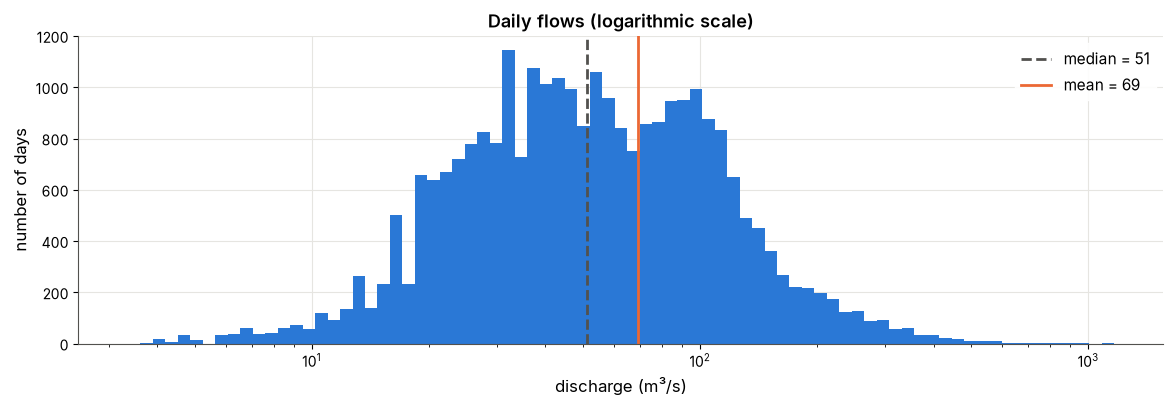

In [7]:
print(flow.describe(percentiles=[0.05, 0.5, 0.95]).round(1).to_string())
print()
print(f'Lowest daily flow:  {flow.min():,.1f} m³/s on {flow.idxmin():%Y-%m-%d}')
print(f'Highest daily flow: {flow.max():,.0f} m³/s on {flow.idxmax():%Y-%m-%d}')
print(f'The mean is {flow.mean() / flow.median():.1f}x the median')

fig, ax = plt.subplots(figsize=(14, 4))
values = flow.dropna()
ax.hist(values, bins=np.logspace(np.log10(values.min()), np.log10(values.max()), 80), color=BLUE)
ax.set_xscale('log')
ax.axvline(values.median(), color=MUTED, linestyle='--', linewidth=2, label=f'median = {values.median():,.0f}')
ax.axvline(values.mean(), color=ORANGE, linewidth=2, label=f'mean = {values.mean():,.0f}')
ax.set_title('Daily flows (logarithmic scale)')
ax.set_xlabel('discharge (m³/s)')
ax.set_ylabel('number of days')
ax.legend()
tidy(ax)
plt.show()

**How to read it:** as in most rivers, a few flood days are many times larger than a typical day, so the distribution is skewed and the mean sits above the median. RHIS-TS uses **non-parametric** tests, which work with the order (rank) of the values, so this skewness is not a problem.

### 3. Is there a seasonal cycle?

Each box summarizes the average flow of one calendar month across all years with complete data for that month.

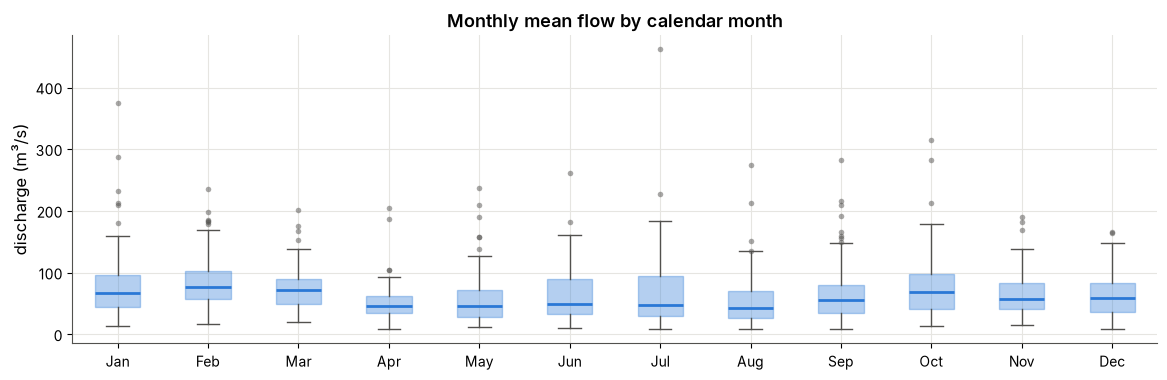

Wettest month (median): Feb (76 m³/s)
Driest month (median):  Aug (43 m³/s)
Ratio wettest/driest:   1.8x


In [8]:
days_with_data = flow.resample('MS').count()
days_in_month = flow.resample('MS').size()
monthly_mean = flow.resample('MS').mean().where(days_with_data == days_in_month)  # complete months only

by_month = [monthly_mean[monthly_mean.index.month == m].dropna().to_numpy() for m in range(1, 13)]
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, ax = plt.subplots(figsize=(14, 4))
ax.boxplot(
    by_month, tick_labels=month_names, widths=0.5, patch_artist=True,
    boxprops={'facecolor': BLUE, 'edgecolor': BLUE, 'alpha': 0.35},
    medianprops={'color': BLUE, 'linewidth': 2},
    whiskerprops={'color': MUTED}, capprops={'color': MUTED},
    flierprops={'marker': 'o', 'markersize': 4, 'markerfacecolor': MUTED, 'markeredgecolor': 'none', 'alpha': 0.5},
)
ax.set_title('Monthly mean flow by calendar month')
ax.set_ylabel('discharge (m³/s)')
tidy(ax)
plt.show()

medians = pd.Series([np.median(v) for v in by_month], index=month_names)
print(f'Wettest month (median): {medians.idxmax()} ({medians.max():,.0f} m³/s)')
print(f'Driest month (median):  {medians.idxmin()} ({medians.min():,.0f} m³/s)')
print(f'Ratio wettest/driest:   {medians.max() / medians.min():.1f}x')

**How to read it:** there is a seasonal cycle (higher flows from October to March, lower from April to August), but it is **mild**: the typical flow of the wettest month is less than twice that of the driest. In southern Brazil it rains in every season, and any month can bring a flood (the largest on record came in July, in winter). Compare with the Potomac, where the wettest month is about eight times the driest.

**Why it matters:** with weaker seasons, the calendar alone explains less of the ups and downs than in the Potomac, but flows still follow a yearly rhythm that the randomness test can pick up on daily and monthly data.

### 4. Does today's flow "remember" yesterday's?

The lag-1 autocorrelation measures how similar each value is to the previous one: 1 means identical, 0 means unrelated. The "monthly anomaly" is each month minus the average for that calendar month, a simple way to remove the seasons.

In [9]:
monthly_anomaly = monthly_mean - monthly_mean.groupby(monthly_mean.index.month).transform('mean')
complete_years = flow.resample('YS').count() >= 365
annual_mean = flow.resample('YS').mean()[complete_years]  # complete years only

series_by_step = {
    'daily': flow,
    'monthly': monthly_mean,
    'monthly anomaly (seasons removed)': monthly_anomaly,
    'annual (complete years)': annual_mean,
}
summary = pd.DataFrame({
    'lag-1 autocorrelation': {k: round(s.autocorr(1), 2) for k, s in series_by_step.items()},
    'number of values': {k: int(s.notna().sum()) for k, s in series_by_step.items()},
})
# Rough threshold: below about 2/sqrt(n), the correlation is indistinguishable from chance
summary['chance level (±2/√n)'] = (2 / np.sqrt(summary['number of values'])).round(2)
summary

,lag-1 autocorrelation,number of values,chance level (±2/√n)
daily,0.96,27814,0.01
monthly,0.50,914,0.07
monthly anomaly (seasons removed),0.52,914,0.07
annual (complete years),0.28,75,0.23


**How to read it:** day-to-day memory is extreme (a river drains slowly), and month-to-month memory is still clear, even with the seasons removed. The annual value is the surprise: unlike the Potomac, where it is close to zero, here it is **above the chance level**. A step change in the record can produce exactly this: if the river was drier for decades and then wetter for decades, each year resembles its neighbors simply because it belongs to the same period. The next question looks at that directly.

### 5. Are there long-term changes?

Annual averages smooth out the seasons and most of the persistence. Only complete years are used; years in the gaps are simply absent.

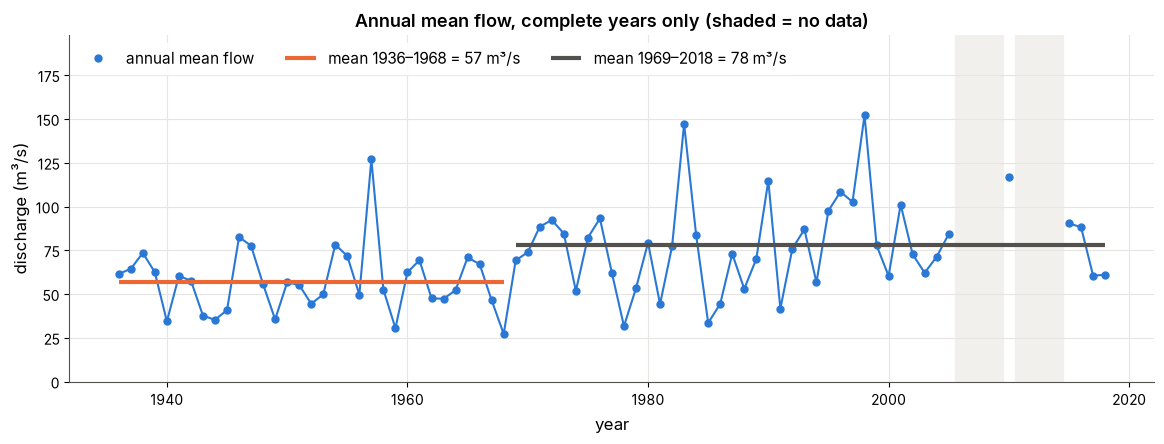

Mean 1936–1968: 57.2 m³/s (33 years)
Mean 1969–2018: 78.0 m³/s (42 years), +36%


In [10]:
years = annual_mean.index.year
before, after = annual_mean[years <= 1968], annual_mean[years >= 1969]

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(annual_mean.index.year, annual_mean, color=BLUE, linewidth=0, marker='o', markersize=5, label='annual mean flow')
ax.plot(annual_mean.loc[:'2005'].index.year, annual_mean.loc[:'2005'], color=BLUE, linewidth=1.5)
ax.plot(annual_mean.loc['2015':].index.year, annual_mean.loc['2015':], color=BLUE, linewidth=1.5)
ax.hlines(before.mean(), before.index.year[0], before.index.year[-1], color=ORANGE, linewidth=3,
          label=f'mean {before.index.year[0]}–{before.index.year[-1]} = {before.mean():.0f} m³/s')
ax.hlines(after.mean(), after.index.year[0], after.index.year[-1], color=MUTED, linewidth=3,
          label=f'mean {after.index.year[0]}–{after.index.year[-1]} = {after.mean():.0f} m³/s')
ax.axvspan(2005.5, 2009.5, color=GAP, zorder=0)
ax.axvspan(2010.5, 2014.5, color=GAP, zorder=0)
ax.set_ylim(0, annual_mean.max() * 1.3)
ax.set_title('Annual mean flow, complete years only (shaded = no data)')
ax.set_xlabel('year')
ax.set_ylabel('discharge (m³/s)')
ax.legend(loc='upper left', ncols=3)
tidy(ax)
plt.show()

print(f'Mean {before.index.year[0]}–{before.index.year[-1]}: {before.mean():.1f} m³/s ({len(before)} years)')
print(f'Mean {after.index.year[0]}–{after.index.year[-1]}: {after.mean():.1f} m³/s ({len(after)} years), '
      f'{after.mean() / before.mean() - 1:+.0%}')

**How to read it:** around 1970 the river becomes clearly wetter: the average flow after 1969 is about a third higher than before. This is a **step** (a shift to a new level), not a gradual slope, and it is not unique to this gauge. Tozzi & Fill (2020) found changes in mean and maximum annual flows across the Iguaçu basin, around 1970 at some gauges and around 1980 at others. For the wider Paraná basin, Conway & Mahé (2009) report flows about 28% higher in 1972–1990 than in 1931–1971, linked to rainfall changes and possibly land use.

### What to expect from the RHIS tests

| What we saw | Assumption affected | Test | Expected outcome |
|---|---|---|---|
| Mild seasonal cycle | Randomness | Wallis-Moore | Likely rejected on daily and monthly data |
| Strong day-to-day and month-to-month memory | Independence | Wald-Wolfowitz | Rejected on daily and monthly data |
| A step to wetter conditions around 1970 | Homogeneity, Stationarity (and Independence on annual data) | Mann-Whitney, Mann-Kendall | **Rejected on the full annual record**; the compliant stretch should start after the step |
| Gaps and raw data after 2005 | all four | — | The most recent stretch, which RHIS-TS favors, is also the least reliable part of the record |

## How RHIS-TS reads a series

RHIS-TS first tests the full record, then drops the oldest value and tests again, and so on until only the 8 most recent values are left. It reports the **longest stretch ending at the most recent value** that passes all four tests at the significance level α (5% here). Missing values are skipped.

The figures have two panels. **Top:** the series (grey) and, in black, the RHIS-compliant stretch. **Bottom:** the p-value of each test for the stretch that **starts** at that date and runs to the end of the record; values below the dashed line (α) mean the test rejects that stretch. The Potomac notebook (`usgs.ipynb`) explains this figure in more detail.

The helpers `run_rhis` and `plot_evolution` (in `helpers.py`) print a plain-language summary and draw the figure; `results` collects every summary for the table at the end.

In [11]:
ALPHA = 0.05
results = {}

## 1. Daily flows

With strong day-to-day memory, no daily stretch is expected to pass. RHIS-TS tests every possible start date: this cell takes one to two minutes.

Daily flow: 27,814 values, 1935-08-07 to 2019-09-30
p-values on the full record: R = <0.001, H = <0.001, I = <0.001, S = <0.001
RHIS-compliant stretch: none (even the last 8 values fail at least one test)


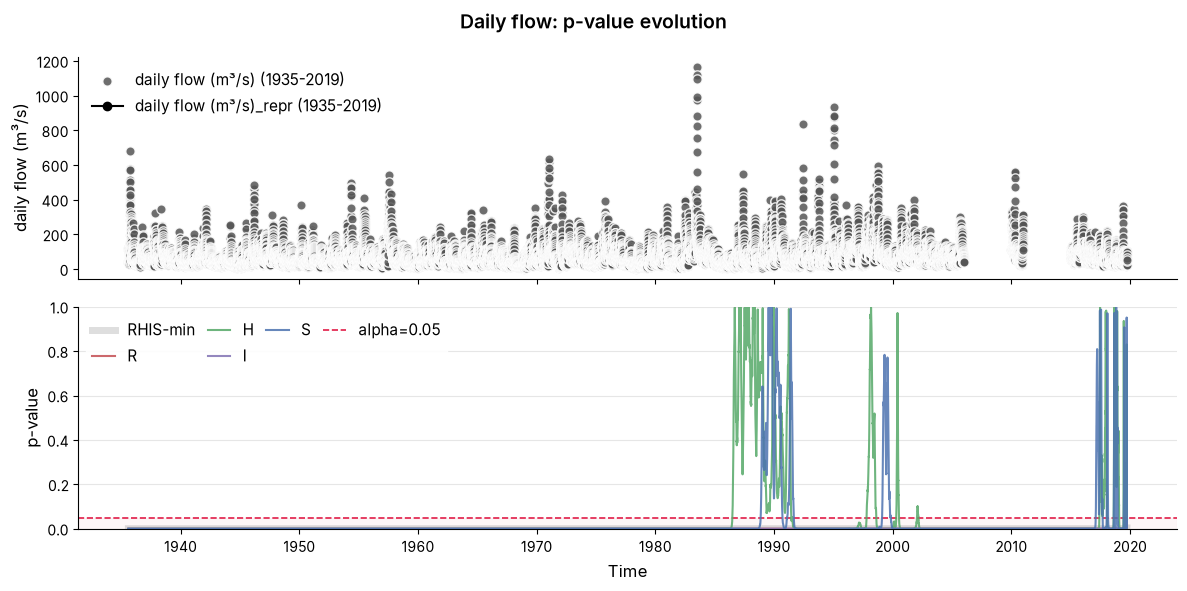

In [12]:
rhis_d, evol_d, repr_d = run_rhis(flow, 'daily flow (m³/s)', 'Daily flow', results, ALPHA)
plot_evolution(rhis_d, evol_d, repr_d, 'Daily flow: p-value evolution', ALPHA)

**Result: no RHIS-compliant stretch**, not even the last 8 days, as expected. All four tests reject the full record. Daily flows are the right input for hydrographs and flow-duration curves, but not for statistics that assume independent values. (The Potomac notebook shows why homogeneity and stationarity rejections on daily data are not, on their own, reliable evidence of change.)

## 2. Monthly flows

Only complete months are used. The seasons are removed in the anomaly series.

Monthly flow: 914 values, 1935-08 to 2019-09
p-values on the full record: R = <0.001, H = <0.001, I = <0.001, S = <0.001
RHIS-compliant stretch: 2016-08 to 2019-09 (38 values, 4% of the record)

Monthly anomaly (seasons removed): 914 values, 1935-08 to 2019-09
p-values on the full record: R = <0.001, H = <0.001, I = <0.001, S = <0.001
RHIS-compliant stretch: 2016-08 to 2019-09 (38 values, 4% of the record)


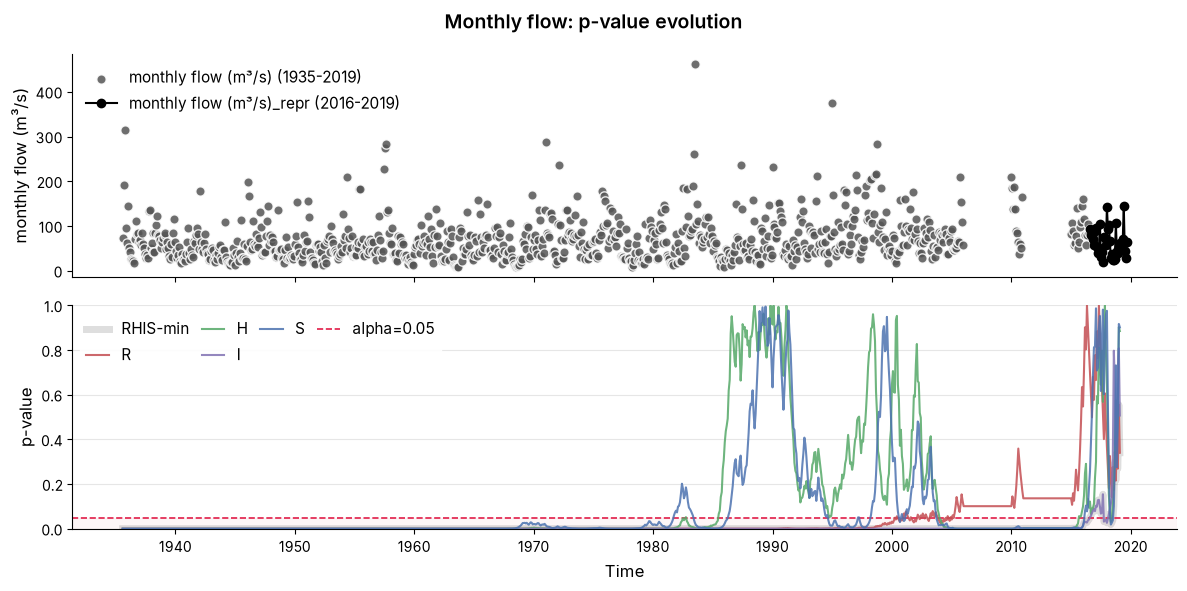

In [13]:
rhis_m, evol_m, repr_m = run_rhis(monthly_mean, 'monthly flow (m³/s)', 'Monthly flow', results, ALPHA, date_fmt='%Y-%m')
print()
rhis_a, evol_a, repr_a = run_rhis(monthly_anomaly, 'monthly anomaly (m³/s)', 'Monthly anomaly (seasons removed)',
                                  results, ALPHA, date_fmt='%Y-%m')
plot_evolution(rhis_m, evol_m, repr_m, 'Monthly flow: p-value evolution', ALPHA)

**Result: only the last three years pass** (August 2016 to September 2019, with or without the seasons). That is too short to represent the wet and dry years a river goes through, and it is made entirely of raw data. As in the Potomac, the monthly scale is not where a representative sample can be found.

## 3. Annual flows

This is the scale used for most planning studies, and where the step seen in exploration should show up.

Annual mean flow: 75 values, 1936 to 2018
p-values on the full record: R = 0.003, H = 0.005, I = 0.007, S = <0.001
RHIS-compliant stretch: 1969 to 2018 (42 values, 56% of the record)


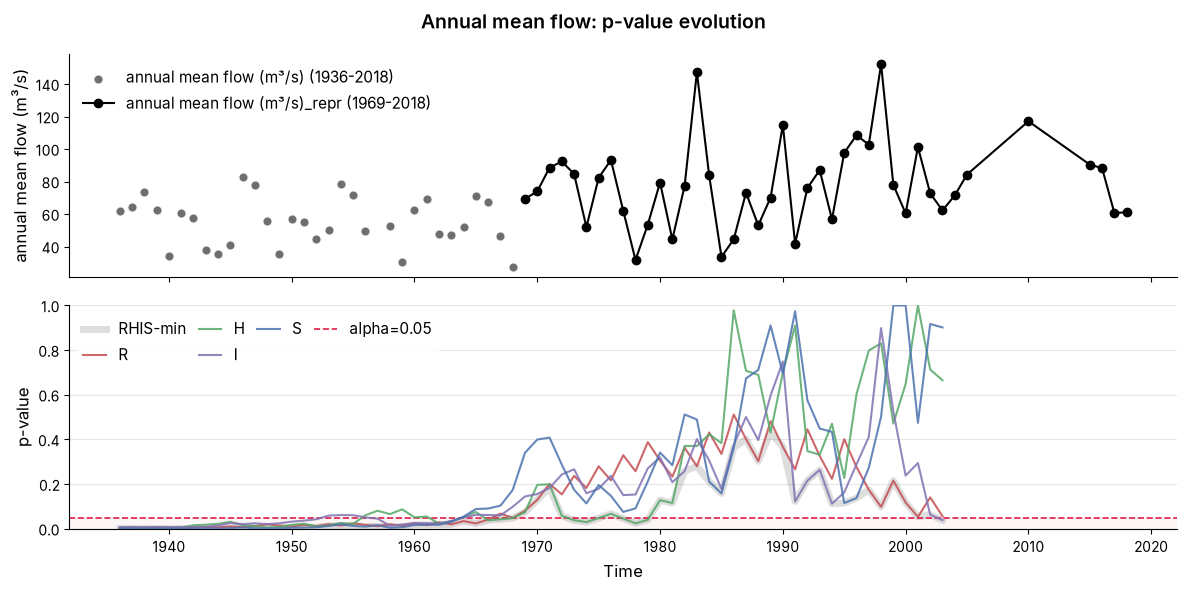

In [14]:
rhis_y, evol_y, repr_y = run_rhis(annual_mean, 'annual mean flow (m³/s)', 'Annual mean flow', results, ALPHA, date_fmt='%Y')
plot_evolution(rhis_y, evol_y, repr_y, 'Annual mean flow: p-value evolution', ALPHA)

**Result: the full record fails all four tests, and the RHIS-compliant stretch starts in 1969.** This is the opposite of the Potomac, where the whole record passed.

The bottom panel shows how the answer builds up: for every start year up to 1968, at least one test rejects (homogeneity and stationarity detect the step; independence and randomness react to the long dry and wet runs it creates). From 1969 on, the stretch contains only the "wetter river", and all four tests pass. A few later start years fail again (between 1973 and 1979, and 2003), but RHIS-TS reports the **longest** passing stretch, 1969–2018.

**What it means:** the 1936–1968 years describe a different river. Mixing them in would underestimate today's typical flow. Note also that the "42 years" of this stretch include the gap years: the tests read 2005, 2010 and 2015 as consecutive values.

## 4. Floods and low flows: the annual extremes

* **Annual maximum flow:** the largest daily flow of each year, the basis of flood-frequency analysis (bridges, levees, floodplain maps).
* **Annual 7-day minimum flow:** the lowest 7-day average flow of each year, the basis of the **Q7,10** (the 7-day low flow expected once every 10 years). In Brazil, low-flow statistics such as the Q7,10 and the Q95 are used as reference flows for water-use permits (*outorga*) and for wastewater discharge limits.

Annual maximum flow: 75 values, 1936 to 2018
p-values on the full record: R = 0.016, H = 0.239, I = 0.274, S = 0.133
RHIS-compliant stretch: 1947 to 2018 (64 values, 85% of the record)


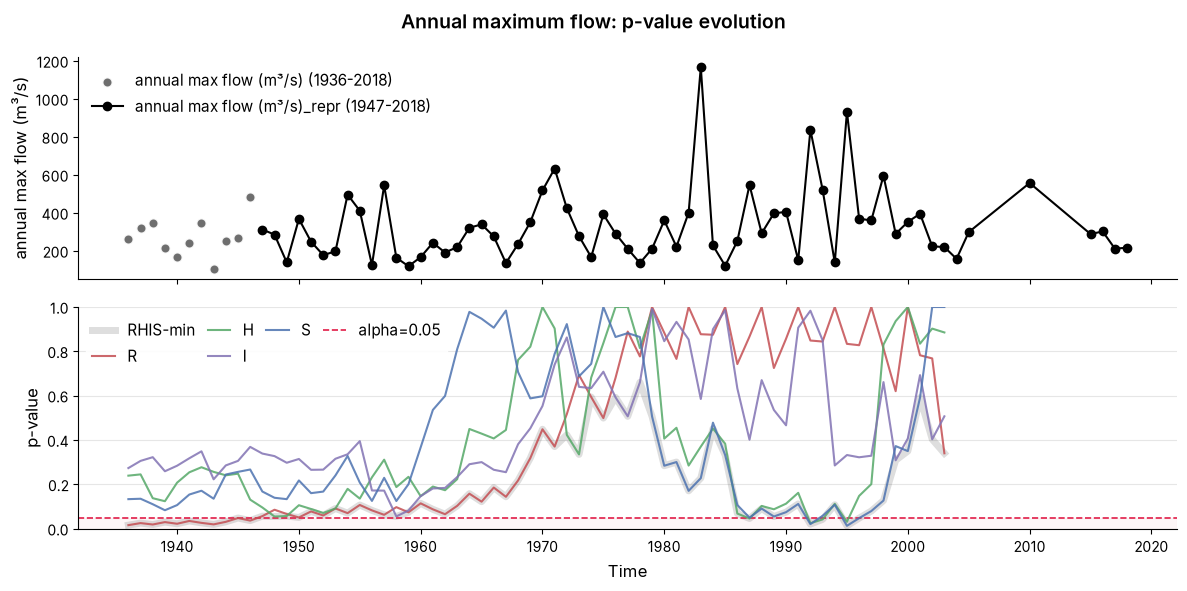

In [15]:
annual_max = flow.resample('YS').max()[complete_years]
annual_min7 = flow.rolling(7).mean().resample('YS').min()[complete_years]  # lowest 7-day average of each year

rhis_max, evol_max, repr_max = run_rhis(annual_max, 'annual max flow (m³/s)', 'Annual maximum flow', results, ALPHA, date_fmt='%Y')
plot_evolution(rhis_max, evol_max, repr_max, 'Annual maximum flow: p-value evolution', ALPHA)

Annual 7-day minimum flow: 75 values, 1936 to 2018
p-values on the full record: R = 0.016, H = 0.089, I = 0.003, S = 0.063
RHIS-compliant stretch: 1989 to 2018 (22 values, 29% of the record)


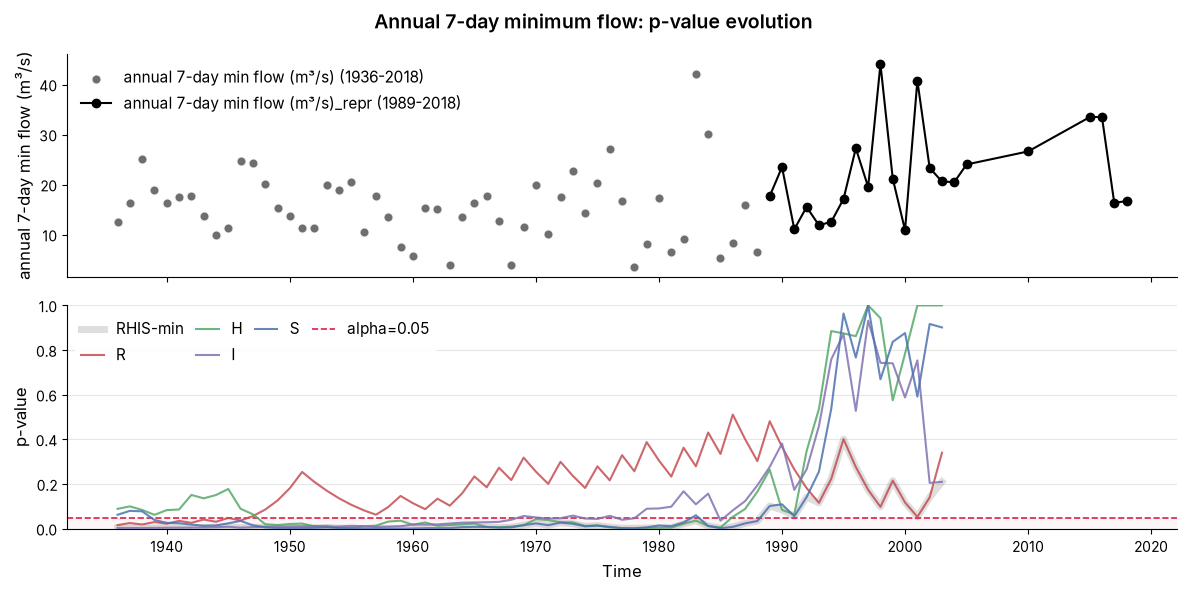

In [16]:
rhis_min7, evol_min7, repr_min7 = run_rhis(annual_min7, 'annual 7-day min flow (m³/s)', 'Annual 7-day minimum flow',
                                           results, ALPHA, date_fmt='%Y')
plot_evolution(rhis_min7, evol_min7, repr_min7, 'Annual 7-day minimum flow: p-value evolution', ALPHA)

**Result:**

* **Floods:** on the full record, only randomness rejects; homogeneity, independence and stationarity pass. The compliant stretch starts in 1947, so most of the record (64 years) can be used for flood frequency.
* **Low flows:** the full record fails, and the compliant stretch starts only in **1989**: just **22 years**, with gaps. That is a short sample for a design low flow, and the next section shows why it is so short.

## 5. What the gaps and the raw recent data do

RHIS-TS anchors every stretch at the most recent value. Here, the most recent values are the raw, gappy ones from 2010 to 2018. To see their effect, let's rerun the annual series on the **consistency-checked record only** (1936–2005) and compare.

In [17]:
checked_only = {}
for series, name, label in [
    (annual_mean, 'annual mean flow (m³/s)', 'Annual mean flow'),
    (annual_max, 'annual max flow (m³/s)', 'Annual maximum flow'),
    (annual_min7, 'annual 7-day min flow (m³/s)', 'Annual 7-day minimum flow'),
]:
    run_rhis(series.loc[:'2005'], name, label, checked_only, ALPHA, date_fmt='%Y')
    print()

comparison = pd.DataFrame({
    'full record: stretch': {k: results[k]['compliant stretch'] for k in checked_only},
    'full record: years': {k: results[k]['compliant values'] for k in checked_only},
    'checked only (to 2005): stretch': {k: v['compliant stretch'] for k, v in checked_only.items()},
    'checked only: years': {k: v['compliant values'] for k, v in checked_only.items()},
})
comparison

Annual mean flow: 70 values, 1936 to 2005
p-values on the full record: R = 0.007, H = <0.001, I = 0.028, S = 0.002
RHIS-compliant stretch: 1964 to 2005 (42 values, 60% of the record)

Annual maximum flow: 70 values, 1936 to 2005
p-values on the full record: R = 0.007, H = 0.070, I = 0.334, S = 0.099
RHIS-compliant stretch: 1955 to 2005 (51 values, 73% of the record)

Annual 7-day minimum flow: 70 values, 1936 to 2005
p-values on the full record: R = 0.035, H = 0.231, I = 0.025, S = 0.276
RHIS-compliant stretch: 1944 to 2005 (62 values, 89% of the record)



,full record: stretch,full record: years,checked only (to 2005): stretch,checked only: years
Annual mean flow,1969 to 2018,42,1964 to 2005,42
Annual maximum flow,1947 to 2018,64,1955 to 2005,51
Annual 7-day minimum flow,1989 to 2018,22,1944 to 2005,62


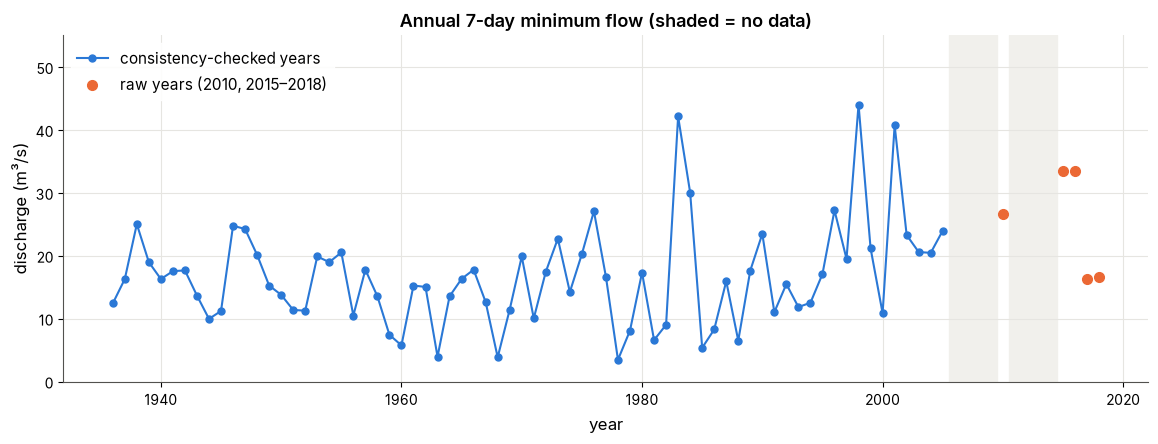

2010:  26.6 m³/s, rank 9 of 75 (1 = highest)
2015:  33.5 m³/s, rank 5 of 75 (1 = highest)
2016:  33.6 m³/s, rank 4 of 75 (1 = highest)
2017:  16.4 m³/s, rank 39 of 75 (1 = highest)
2018:  16.7 m³/s, rank 36 of 75 (1 = highest)
Mean 1944–2005: 16.6 m³/s | mean of the raw years: 25.3 m³/s


In [18]:
recent = annual_min7.loc['2010':]
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(annual_min7.loc[:'2005'].index.year, annual_min7.loc[:'2005'], color=BLUE, marker='o', markersize=5,
        linewidth=1.5, label='consistency-checked years')
ax.plot(recent.index.year, recent, color=ORANGE, marker='o', markersize=7, linewidth=0, label='raw years (2010, 2015–2018)')
ax.axvspan(2005.5, 2009.5, color=GAP, zorder=0)
ax.axvspan(2010.5, 2014.5, color=GAP, zorder=0)
ax.set_ylim(0, annual_min7.max() * 1.25)
ax.set_title('Annual 7-day minimum flow (shaded = no data)')
ax.set_xlabel('year')
ax.set_ylabel('discharge (m³/s)')
ax.legend(loc='upper left')
tidy(ax)
plt.show()

rank = annual_min7.rank(ascending=False)  # 1 = highest low flow
for year, value in recent.items():
    print(f'{year:%Y}: {value:5.1f} m³/s, rank {int(rank[year])} of {len(annual_min7)} (1 = highest)')
print(f'Mean 1944–2005: {annual_min7.loc["1944":"2005"].mean():.1f} m³/s | mean of the raw years: {recent.mean():.1f} m³/s')

**How to read it:**

* **Annual means and floods** shift by a few years without the recent raw data (from 1969 to 1964 for means, from 1947 to 1955 for floods), but the picture stays the same: a consistent stretch after the step for means, most of the record for floods.
* **Low flows change completely.** With the checked data alone, the compliant stretch covers more than 60 years (from 1944). Adding five raw years shortens it to 22. The checked data already show higher low flows from the 1980s on (and Tozzi & Fill, 2020, found changes in minimum flows at some Iguaçu gauges), but not enough for the tests to reject. Three of the five raw years (2010, 2015 and 2016) then rank among the **highest low flows of the whole record**, and the upward shift becomes significant.

RHIS-TS cannot say *why* those years look different. It might be a real change in how the river behaves in dry periods, or an artifact of data that have not yet been checked (low flows are especially sensitive to the bottom of the rating curve). What RHIS-TS does is flag that the most recent part of the record does not look like the rest, which is precisely the information needed before choosing a design low flow.

**Practical lesson:** before trusting the recent end of a record, check how much of it is raw and whether it has gaps. When it matters, compare the result with and without that part, as done here, and confirm with the data provider or with neighboring gauges.

## 6. Why it matters: design values from the full record vs. the compliant stretch

How much does the choice of sample change the numbers a water manager would use? Three common design values, each estimated from the full record and from the RHIS-compliant stretch. Floods and the Q7,10 use the log-Pearson type III distribution; the 90% range comes from bootstrap resampling and shows how much the estimate could change just by chance in which years were observed.

In [19]:
def estimate_row(design_value, sample_name, sample, prob=None):
    if prob is None:  # long-term mean flow
        value, low, high = sample.mean(), np.nan, np.nan
    else:
        value, low, high = lp3_estimate(sample, prob)
    return {
        'design value': design_value,
        'sample': f'{sample_name}, {sample.index[0]:%Y}–{sample.index[-1]:%Y} ({len(sample)} years)',
        'estimate (m³/s)': round(value, 1),
        '90% range (m³/s)': '' if np.isnan(low) else f'{low:.1f} – {high:.1f}',
    }


rows = [
    estimate_row('Mean annual flow', 'full record', annual_mean),
    estimate_row('Mean annual flow', 'RHIS-compliant stretch', annual_mean.loc['1969':]),
    estimate_row('100-year flood', 'full record', annual_max, 0.99),
    estimate_row('100-year flood', 'RHIS-compliant stretch', annual_max.loc['1947':], 0.99),
    estimate_row('Q7,10 low flow', 'full record', annual_min7, 0.10),
    estimate_row('Q7,10 low flow', 'RHIS-compliant stretch (with raw years)', annual_min7.loc['1989':], 0.10),
    estimate_row('Q7,10 low flow', 'RHIS-compliant stretch (checked data only)', annual_min7.loc['1944':'2005'], 0.10),
]
pd.DataFrame(rows).set_index(['design value', 'sample'])

estimate (m³/s)  \
design value     sample                                                                
Mean annual flow full record, 1936–2018 (75 years)                              68.8   
                 RHIS-compliant stretch, 1969–2018 (42 years)                   78.0   
100-year flood   full record, 1936–2018 (75 years)                            1020.2   
                 RHIS-compliant stretch, 1947–2018 (64 years)                 1093.6   
Q7,10 low flow   full record, 1936–2018 (75 years)                               7.6   
                 RHIS-compliant stretch (with raw years), 1989–2...             12.5   
                 RHIS-compliant stretch (checked data only), 194...              7.0   

                                                                    90% range (m³/s)  
design value     sample                                                               
Mean annual flow full record, 1936–2018 (75 years)                                    
                 RHIS-compliant stretch, 1969–2018 (42 years)                         
100-year flood   full record, 1936–2018 (75 years)                    741.0 – 1307.6  
                 RHIS-compliant stretch, 1947–2018 (64 years)         778.8 – 1414.0  
Q7,10 low flow   full record, 1936–2018 (75 years)                         6.5 – 9.2  
                 RHIS-compliant stretch (with raw years), 1989–2...      11.0 – 14.9  
                 RHIS-compliant stretch (checked data only), 194...        5.9 – 8.7

**How to read it:**

* **Mean annual flow:** the full record underestimates today's typical flow by more than 10%, because it mixes in the drier decades before 1970. For water availability studies, the RHIS-compliant stretch is the better sample.
* **100-year flood:** the two estimates differ by less than 10%, well inside each other's uncertainty range. For floods, the full record and the compliant stretch lead to similar designs.
* **Q7,10:** this is where the choice matters most, and where it must be made with care. The stretch that includes the raw recent years gives a Q7,10 more than 60% higher than the full record; the stretch based on checked data only gives a value close to the full record. A higher reference low flow allows more water to be withdrawn or more wastewater to be discharged, so it should not rest on five unchecked years.

*Note:* the fit is deliberately simple (method of moments, skew from this gauge only) to compare samples, not to replace a full design study.

## Summary of results

In [20]:
pd.DataFrame(results).T

,values,R (full record),H (full record),I (full record),S (full record),compliant stretch,compliant values,share of record
Daily flow,27814,<0.001,<0.001,<0.001,<0.001,none,0,0%
Monthly flow,914,<0.001,<0.001,<0.001,<0.001,2016-08 to 2019-09,38,4%
Monthly anomaly (seasons removed),914,<0.001,<0.001,<0.001,<0.001,2016-08 to 2019-09,38,4%
Annual mean flow,75,0.003,0.005,0.007,<0.001,1969 to 2018,42,56%
Annual maximum flow,75,0.016,0.239,0.274,0.133,1947 to 2018,64,85%
Annual 7-day minimum flow,75,0.016,0.089,0.003,0.063,1989 to 2018,22,29%


## Conclusions and implications for water resources management

**Expected vs. observed**

| Series | Expected | Observed |
|---|---|---|
| Daily flow | Randomness and independence rejected | No compliant stretch |
| Monthly flow (with or without seasons) | Randomness and independence rejected | Only the last 3 years pass, all raw data |
| Annual mean flow | Rejected because of the step around 1970 | Full record fails all four tests; compliant from 1969 |
| Annual maximum flow | Possibly affected by the step | Compliant from 1947 (64 years) |
| Annual 7-day minimum flow | — | Compliant only from 1989 (22 years); from 1944 with checked data only |

**Main conclusions**

1. **This record is not one sample.** The Iguaçu at Porto Amazonas became wetter around 1970, and RHIS-TS finds that the annual record is consistent only from 1969 on. Studies of current water availability should use that stretch rather than the full record. The finding agrees with earlier studies of the Iguaçu and Paraná basins (Tozzi & Fill, 2020; Conway & Mahé, 2009).
2. **Different variables, different answers.** Floods are consistent over most of the record (from 1947), mean flows only after the step, and low flows depend on the recent data. Each design variable should be tested on its own.
3. **The recent end of a record deserves extra scrutiny.** RHIS-TS favors recent data by design. When those data are raw and gappy, as here after 2005, they can decide the result. Testing with and without them is a simple and revealing check.
4. **The choice of sample changes design values.** The mean annual flow is more than 10% higher in the compliant stretch than in the full record, and the Q7,10 can differ by more than 60% depending on whether unchecked years are included.
5. **Compare rivers, don't assume.** The Potomac record passed as a whole; the Iguaçu record does not. The same method gives different answers because the rivers really differ, which is exactly why each record should be tested.

**Limits to keep in mind.** Not rejecting an assumption does not prove it is true: with few values, the tests can miss real changes. RHIS-TS shows *where* the record stops looking consistent, not *why*: the causes (rainfall, land use, river regulation, data quality) need hydrological investigation.

## References

* Conway, D.; Mahé, G. (2009). River flow modelling in two large river basins with non-stationary behaviour: the Paraná and the Niger. *Hydrological Processes*, 23(22), 3186–3192. https://doi.org/10.1002/hyp.7393
* Tozzi, B. K. M.; Fill, H. D. O. A. (2020). Verification of the stationarity of flow series in the Iguaçu River basin. *Revista Brasileira de Recursos Hídricos*, 25. https://doi.org/10.1590/2318-0331.252020180171
* ANA, Agência Nacional de Águas e Saneamento Básico. HidroWeb: station 65035000 (Porto Amazonas). https://www.snirh.gov.br/hidroweb